# класифікація EEG: людина думає про цифру 6 чи 7?

**датасет:** MindBigData «MNIST of Brain Digits», файл гарнітури Emotiv EPOC (`EP1.01.txt`, 14 каналів, 128 Гц, ~2 с на запис)

**задача:** бінарна класифікація — за сигналом мозку визначити, яку цифру (6 чи 7) бачила й уявляла людина

1. **логістична регресія** — проста лінійна модель на готових ознаках
2. **random forest** — ансамбль дерев рішень на тих самих ознаках
3. **згорткова нейромережа (1D-CNN)** — сама шукає закономірності в сирому сигналі

класифікуємо цифри. можна змінити `DIGITS = [6, 7]` на інші

In [25]:
import os, glob, time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.stats import binomtest

DIGITS = [6, 7]
FS = 128
N_SAMPLES = 250
RANDOM_STATE = 42

CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
            "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]

np.random.seed(RANDOM_STATE)

colab сам скачує датасет із kaggle. у `DATA_FILE` можна вручну вписати шлях до файлу

In [26]:
import kagglehub

path = kagglehub.dataset_download("vijayveersingh/1-2m-brain-signal-data")
files = glob.glob(os.path.join(path, "**", "EP*.txt"), recursive=True)
DATA_FILE = files[0]
print("Файл:", DATA_FILE)
print(f"Розмір: {os.path.getsize(DATA_FILE) / 1e9:.2f} ГБ")

Using Colab cache for faster access to the '1-2m-brain-signal-data' dataset.
Файл: /kaggle/input/1-2m-brain-signal-data/MindBigData-EP-v1.0/EP1.01.txt
Розмір: 2.86 ГБ


### як влаштований файл

кожен рядок — це один канал одного запису, поля розділені табуляцією:

| id | event | device | channel | code | size | data |
|---|---|---|---|---|---|---|
| номер рядка | номер запису | `EP` | назва датчика, напр. `O1` | цифра (або -1) | кількість значень | сигнал через кому |

один показ цифри = 14 рядків з однаковим `event`. Функція нижче читає файл рядок за рядком, залишає лише потрібні цифри і збирає 14 каналів назад в один приклад розміром `14 × 250`

In [27]:
def load_epoc(filename, digits, n_samples=N_SAMPLES):
    wanted = set(str(d) for d in digits)
    events = defaultdict(dict)
    labels = {}
    with open(filename, "r") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) < 7:
                continue
            _id, event, device, channel, code, size, data = parts[:7]
            if code.strip() not in wanted:
                continue
            values = np.array(data.split(","), dtype=np.float32)
            if len(values) < n_samples:
                continue
            events[event][channel.strip()] = values[:n_samples]
            labels[event] = int(code)

    X, y = [], []
    for event, chans in events.items():
        if all(ch in chans for ch in CHANNELS):
            X.append(np.stack([chans[ch] for ch in CHANNELS]))
            y.append(labels[event])
    return np.array(X, dtype=np.float32), np.array(y)

t0 = time.time()
X, y = load_epoc(DATA_FILE, DIGITS)
print(f"прочитано за {time.time() - t0:.0f} с")
print("форма X:", X.shape, " (записи × канали × відліки)")
print("к-ть записів кожної цифри:")
print(pd.Series(y).value_counts().sort_index())

прочитано за 36 с
форма X: (12853, 14, 250)  (записи × канали × відліки)
к-ть записів кожної цифри:
6    6520
7    6333
Name: count, dtype: int64


## огляд даних

сирі значення з гарнітури мають великий постійний зсув (близько 4000). він не несе інформації про цифру, тому для кожного запису і каналу віднімаємо середнє

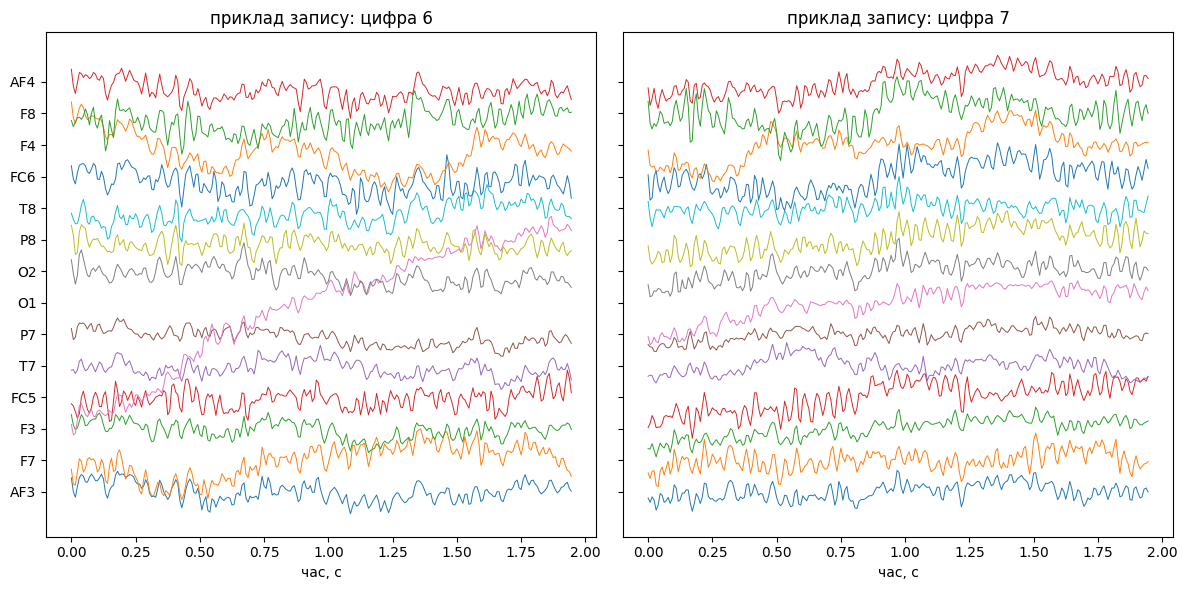

In [28]:
X = X - X.mean(axis=2, keepdims=True)

fig, axes = plt.subplots(1, len(DIGITS), figsize=(6 * len(DIGITS), 6), sharey=True)
t = np.arange(N_SAMPLES) / FS
for ax, d in zip(np.atleast_1d(axes), DIGITS):
    sample = X[np.where(y == d)[0][0]]
    offset = 4 * np.median(np.abs(sample)) + 1e-6
    for i, ch in enumerate(CHANNELS):
        ax.plot(t, sample[i] + i * offset, lw=0.7)
    ax.set_yticks([i * offset for i in range(len(CHANNELS))])
    ax.set_yticklabels(CHANNELS)
    ax.set_xlabel("час, с")
    ax.set_title(f"приклад запису: цифра {d}")
plt.tight_layout()
plt.show()

## розподіл на навчальну і тестову вибірки

80% записів — для навчання, 20% — для перевірки. розподіл стратифікований: частка шісток і сімок однакова в обох частинах

цей самий розподіл використовують усі три моделі, тому їх доцільно порівнювати

In [29]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(y))
idx_train, idx_test = train_test_split(idx, test_size=0.2, stratify=y,
                                       random_state=RANDOM_STATE)
y_train, y_test = y[idx_train], y[idx_test]
print("навчальна вибірка:", len(idx_train), " тестова:", len(idx_test))

chance = pd.Series(y_test).value_counts(normalize=True).max()
print(f"рівень випадковості на тесті: {chance:.3f}")

навчальна вибірка: 10282  тестова: 2571
рівень випадковості на тесті: 0.507


## ознаки: потужність у частотних діапазонах

сирий запис — це 14 × 250 = 3500 чисел. для простих моделей це забагато, тому ми «стискаємо» сигнал до змістовних ознак

мозкова активність складається з коливань різної частоти: дельта (1–4 Гц), тета (4–8), альфа (8–13), бета (13–30), гамма (30–45). для кожного каналу рахуємо, скільки енергії сигналу припадає на кожен діапазон, і беремо логарифм

отримуємо 14 каналів × 5 діапазонів = 70 ознак на запис


In [30]:
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13),
         "beta": (13, 30), "gamma": (30, 45)}

def band_power_features(X):
    freqs, psd = welch(X, fs=FS, nperseg=128, axis=-1)
    feats = []
    for lo, hi in BANDS.values():
        mask = (freqs >= lo) & (freqs < hi)
        feats.append(np.log(psd[:, :, mask].mean(axis=-1) + 1e-10))
    return np.concatenate(feats, axis=1)

F = band_power_features(X)
feature_names = [f"{ch}_{band}" for band in BANDS for ch in CHANNELS]
F_train, F_test = F[idx_train], F[idx_test]
print("форма матриці ознак:", F.shape)

форма матриці ознак: (12853, 70)


## допоміжна функція для оцінки моделей

для кожної моделі виводимо:
- accuracy — частку правильних відповідей на тестовій вибірці
- classification report — precision/recall для кожного класу
- матрицю помилок — скільки шісток модель назвала сімками і навпаки

In [31]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

results = {}

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    results[name] = {"accuracy": acc, "n_correct": int((y_true == y_pred).sum())}
    print(f"=== {name}: accuracy на тесті = {acc:.3f} (випадковість = {chance:.3f}) ===")
    print(classification_report(y_true, y_pred, digits=3, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, cmap="Blues")
    plt.title(name)
    plt.show()

## baseline

«модель», яка завжди відповідає найчастішим класом. будь-яка справжня модель має бути кращою за неї, інакше вона нічого не навчилась

=== baseline: accuracy на тесті = 0.507 (випадковість = 0.507) ===
              precision    recall  f1-score   support

           6      0.507     1.000     0.673      1304
           7      0.000     0.000     0.000      1267

    accuracy                          0.507      2571
   macro avg      0.254     0.500     0.337      2571
weighted avg      0.257     0.507     0.341      2571



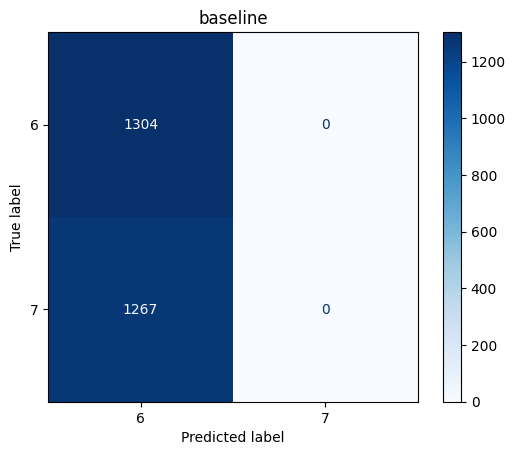

In [32]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(F_train, y_train)
evaluate("baseline", y_test, dummy.predict(F_test))

## модель 1 — логістична регресія (проста)

лінійна модель: кожній із 70 ознак присвоює вагу, зважена сума перетворюється на ймовірність класу. перед цим ознаки стандартизуються (середнє 0, стандартне відхилення 1), щоб жодна не домінувала через масштаб

додатково рахуємо 5-кратну крос-валідацію на навчальній вибірці: модель навчається 5 разів на різних частинах даних, і ми бачимо, наскільки стабільний результат

крос-валідація: 0.550 ± 0.010
=== логістична регресія: accuracy на тесті = 0.524 (випадковість = 0.507) ===
              precision    recall  f1-score   support

           6      0.528     0.567     0.547      1304
           7      0.518     0.479     0.498      1267

    accuracy                          0.524      2571
   macro avg      0.523     0.523     0.522      2571
weighted avg      0.523     0.524     0.523      2571



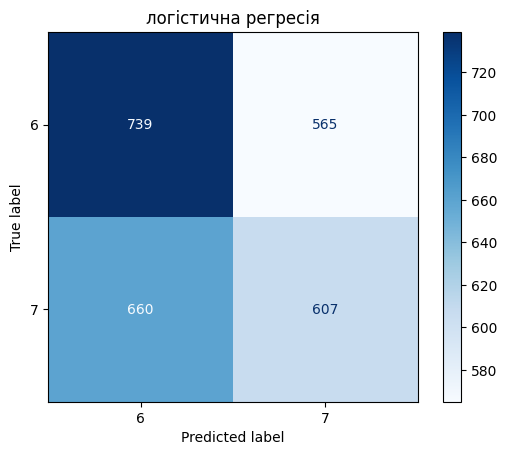

In [33]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1))
cv_scores = cross_val_score(logreg, F_train, y_train, cv=cv)
print(f"крос-валідація: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

logreg.fit(F_train, y_train)
evaluate("логістична регресія", y_test, logreg.predict(F_test))

## модель 2 — random forest (середня складність)

300 дерев рішень, кожне навчається на випадковій підвибірці даних і ознак, а потім вони «голосують». на відміну від логістичної регресії, рандом форест уміє знаходити нелінійні залежності


крос-валідація: 0.531 ± 0.013
=== random forest: accuracy на тесті = 0.534 (випадковість = 0.507) ===
              precision    recall  f1-score   support

           6      0.538     0.587     0.561      1304
           7      0.531     0.480     0.504      1267

    accuracy                          0.534      2571
   macro avg      0.534     0.534     0.533      2571
weighted avg      0.534     0.534     0.533      2571



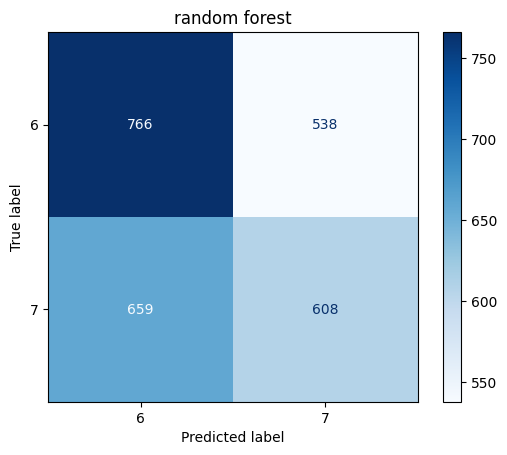

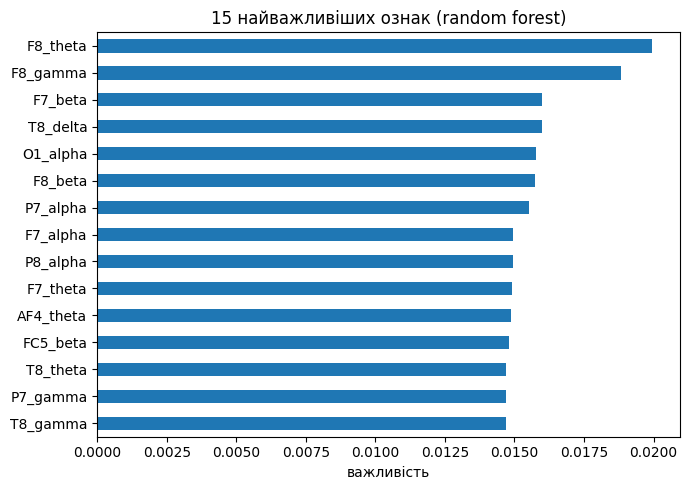

In [34]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                            n_jobs=-1, random_state=RANDOM_STATE)
cv_scores = cross_val_score(rf, F_train, y_train, cv=cv)
print(f"крос-валідація: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

rf.fit(F_train, y_train)
evaluate("random forest", y_test, rf.predict(F_test))

imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values()
imp.tail(15).plot.barh(figsize=(7, 5), title="15 найважливіших ознак (random forest)")
plt.xlabel("важливість")
plt.tight_layout()
plt.show()

## модель 3 — згорткова нейромережа 1D-CNN (складна)

ця модель не використовує наші 70 ознак. вона отримує сирий сигнал (14 каналів × 250 відліків) і сама вчиться, які патерни в часі відрізняють класи

архітектура: три згорткові шари (шукають локальні візерунки в сигналі) → усереднення по часу → лінійний шар, що видає відповідь. dropout і weight decay зменшують перенавчання

частину навчальних даних (15%) відкладаємо як валідаційну вибірку: після кожної епохи перевіряємо на ній точність і зберігаємо найкращу версію моделі. тестову вибірку модель не бачить до самого кінця

In [35]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("пристрій:", device)
torch.manual_seed(RANDOM_STATE)

classes = np.array(sorted(DIGITS))
y_idx = np.searchsorted(classes, y)

idx_tr, idx_val = train_test_split(idx_train, test_size=0.15, stratify=y[idx_train],
                                   random_state=RANDOM_STATE)

mean = X[idx_tr].mean(axis=(0, 2), keepdims=True)
std = X[idx_tr].std(axis=(0, 2), keepdims=True) + 1e-6
Xn = ((X - mean) / std).astype(np.float32)

def make_loader(indices, shuffle):
    ds = TensorDataset(torch.from_numpy(Xn[indices]), torch.from_numpy(y_idx[indices]).long())
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

train_loader = make_loader(idx_tr, shuffle=True)
val_loader = make_loader(idx_val, shuffle=False)
test_loader = make_loader(idx_test, shuffle=False)

пристрій: cuda


In [36]:
class SmallEEGCNN(nn.Module):
    def __init__(self, n_channels=len(CHANNELS), n_classes=len(DIGITS)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_channels, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(0.3),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(0.3),
            nn.Conv1d(64, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        return self.net(x)

def predict(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(device)).argmax(dim=1).cpu().numpy())
    return np.concatenate(preds)

model = SmallEEGCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)
loss_fn = nn.CrossEntropyLoss()
n_params = sum(p.numel() for p in model.parameters())
print(f"к-ть параметрів моделі: {n_params:,}")

EPOCHS = 40
history = {"train_loss": [], "val_acc": []}
best_val, best_state = 0.0, None

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    train_loss = total_loss / len(train_loader.dataset)
    val_acc = accuracy_score(y_idx[idx_val], predict(model, val_loader))
    history["train_loss"].append(train_loss)
    history["val_acc"].append(val_acc)
    if val_acc > best_val:
        best_val = val_acc
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    if epoch % 5 == 0 or epoch == 1:
        print(f"епоха {epoch:2d}: loss = {train_loss:.4f}, accuracy на валідації = {val_acc:.3f}")

model.load_state_dict(best_state)
print(f"найкраща accuracy на валідації: {best_val:.3f}")

к-ть параметрів моделі: 34,466
епоха  1: loss = 0.6999, accuracy на валідації = 0.496
епоха  5: loss = 0.6830, accuracy на валідації = 0.552
епоха 10: loss = 0.6734, accuracy на валідації = 0.553
епоха 15: loss = 0.6695, accuracy на валідації = 0.524
епоха 20: loss = 0.6653, accuracy на валідації = 0.521
епоха 25: loss = 0.6644, accuracy на валідації = 0.540
епоха 30: loss = 0.6621, accuracy на валідації = 0.539
епоха 35: loss = 0.6608, accuracy на валідації = 0.542
епоха 40: loss = 0.6591, accuracy на валідації = 0.535
найкраща accuracy на валідації: 0.564


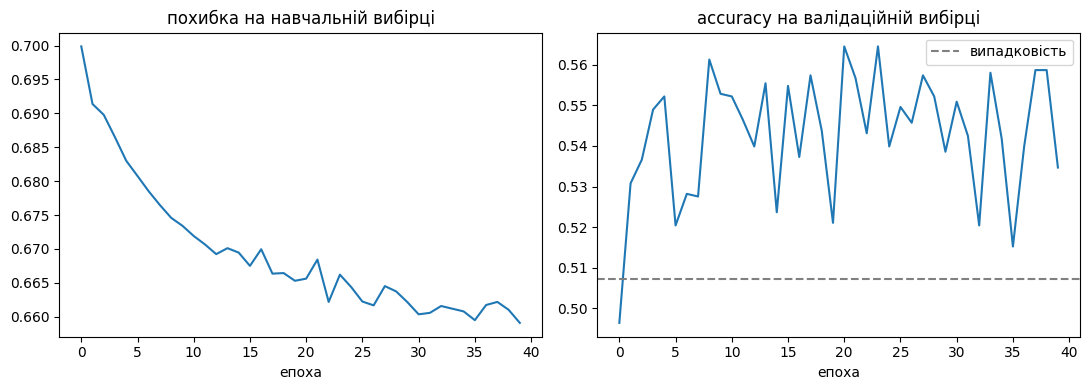

=== 1D-CNN: accuracy на тесті = 0.576 (випадковість = 0.507) ===
              precision    recall  f1-score   support

           6      0.590     0.538     0.563      1304
           7      0.564     0.615     0.588      1267

    accuracy                          0.576      2571
   macro avg      0.577     0.577     0.576      2571
weighted avg      0.577     0.576     0.575      2571



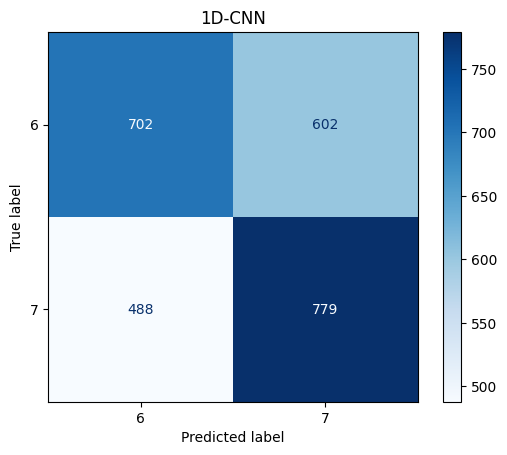

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(history["train_loss"]); ax1.set_title("похибка на навчальній вибірці"); ax1.set_xlabel("епоха")
ax2.plot(history["val_acc"]); ax2.axhline(chance, ls="--", c="gray", label="випадковість")
ax2.set_title("accuracy на валідаційній вибірці"); ax2.set_xlabel("епоха"); ax2.legend()
plt.tight_layout()
plt.show()

y_pred_cnn = classes[predict(model, test_loader)]
evaluate("1D-CNN", y_test, y_pred_cnn)

## порівняння моделей

таблиця і графік з accuracy усіх моделей на тій самій тестовій вибірці

колонка p-value відповідає на питання: «наскільки ймовірно отримати такий результат, якщо модель насправді вгадує навмання?» (біноміальний тест). якщо p-value < 0.05, можна казати, що модель статистично значуще краща за випадковість

,модель,accuracy,p-value (vs випадковість)
0,baseline,0.5072,0.5079
1,логістична регресія,0.5235,0.0508
2,random forest,0.5344,0.0030
3,1D-CNN,0.5760,0.0000


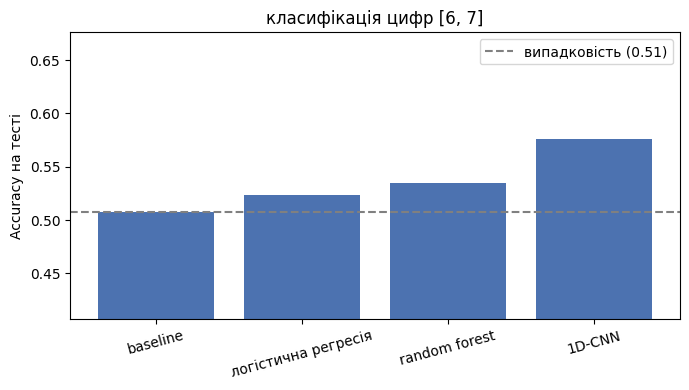

In [38]:
n_test = len(y_test)
table = pd.DataFrame([
    {"модель": name,
     "accuracy": r["accuracy"],
     "p-value (vs випадковість)": binomtest(r["n_correct"], n_test, chance, alternative="greater").pvalue}
    for name, r in results.items()
])
display(table.round(4))

plt.figure(figsize=(7, 4))
plt.bar(table["модель"], table["accuracy"], color="#4C72B0")
plt.axhline(chance, ls="--", c="gray", label=f"випадковість ({chance:.2f})")
plt.ylim(max(0, chance - 0.1), min(1, table["accuracy"].max() + 0.1))
plt.ylabel("Accuracy на тесті")
plt.title(f"класифікація цифр {DIGITS}")
plt.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# покращення моделей

спроба підняти якість була реалізована трьома способами:

1. чистка сигналу: смуговий фільтр 1–45 Гц і відкидання записів з артефактами (моргання, рухи голови)
2. кращі ознаки для простих моделей: вузькі частотні смуги по 2 Гц і відносна потужність
3. для нейромережі: аугментація даних і ансамбль із 5 мереж

тестова вибірка залишається тією самою, що й вище (ті самі 2571 записи, без чистки), тож результати «до» і «після» можна порівнювати напряму. усі рішення приймаються лише за навчальною або валідаційною вибіркою. на тест дивимось тільки в кінці

## фільтрація і відкидання артефактів

смуговий фільтр  прибирає повільний дрейф сигналу (< 1 Гц) і високочастотний шум та наводки (> 45 Гц). наші частотні ознаки й так дивляться лише на 1–45 Гц, тому фільтр насамперед допомагає нейромережі, яка працює із сирим сигналом

артефакти. моргання чи рух голови дають величезні сплески амплітуди, набагато більші за справжню мозкову активність. для кожного запису рахуємо розмах (максимум − мінімум) і відкидаємо 5% записів із найбільшим розмахом, але лише з навчальної вибірки: так моделі вчаться на чистіших прикладах, а тест лишається незмінним

роріг розмаху: 231.3
навчальна вибірка: 10282 -> 9767 записів після чистки


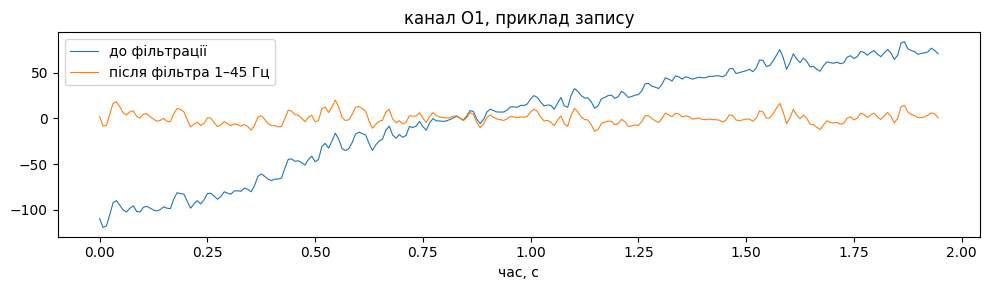

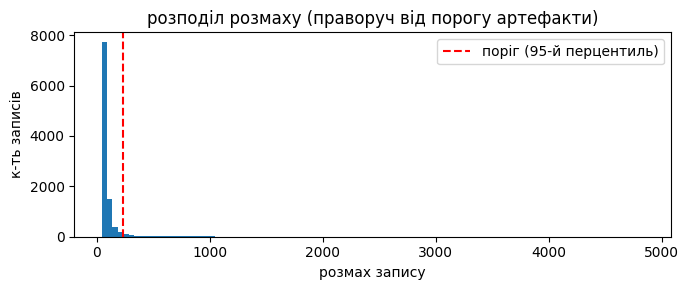

In [39]:
from scipy.signal import butter, sosfiltfilt

sos = butter(4, [1, 45], btype="bandpass", fs=FS, output="sos")
Xf = sosfiltfilt(sos, X, axis=-1).astype(np.float32)

ptp = np.ptp(Xf, axis=2).max(axis=1)
threshold = np.percentile(ptp[idx_train], 95)
idx_train_clean = idx_train[ptp[idx_train] <= threshold]
print(f"поріг розмаху: {threshold:.1f}")
print(f"навчальна вибірка: {len(idx_train)} -> {len(idx_train_clean)} записів після чистки")

ch = CHANNELS.index("O1")
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, X[0, ch], lw=0.8, label="до фільтрації")
ax.plot(t, Xf[0, ch], lw=0.8, label="після фільтра 1–45 Гц")
ax.set_xlabel("час, с"); ax.set_title("канал O1, приклад запису"); ax.legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 3))
plt.hist(ptp[idx_train], bins=100)
plt.axvline(threshold, c="red", ls="--", label="поріг (95-й перцентиль)")
plt.xlabel("розмах запису"); plt.ylabel("к-ть записів")
plt.title("розподіл розмаху (праворуч від порогу артефакти)"); plt.legend()
plt.tight_layout(); plt.show()

## кращі ознаки для логістичної регресії та random forest

замість 5 широких діапазонів беремо 22 вузькі смуги по 2 Гц (1–3, 3–5, …, 43–45 Гц). так модель бачить тонші відмінності в спектрі. додаємо відносну потужність у 5 класичних діапазонах (частку енергії діапазону від загальної), вона менше залежить від того, наскільки добре електрод прилягав до голови в конкретний день

разом: 14 × 22 + 14 × 5 = 378 ознак

для логістичної регресії силу регуляризації `C` тепер підбираємо автоматично крос-валідацією на навчальній вибірці (`LogisticRegressionCV`), а не задаємо вручну

In [40]:
from sklearn.linear_model import LogisticRegressionCV

NARROW = [(lo, lo + 2) for lo in range(1, 45, 2)]

def better_features(X):
    freqs, psd = welch(X, fs=FS, nperseg=128, axis=-1)
    total = psd[:, :, (freqs >= 1) & (freqs < 45)].sum(axis=-1)
    narrow = [np.log(psd[:, :, (freqs >= lo) & (freqs < hi)].mean(axis=-1) + 1e-10)
              for lo, hi in NARROW]
    relative = [np.log(psd[:, :, (freqs >= lo) & (freqs < hi)].sum(axis=-1) / (total + 1e-10) + 1e-10)
                for lo, hi in BANDS.values()]
    return np.concatenate(narrow + relative, axis=1)

flat = (np.ptp(Xf, axis=2) == 0).any(axis=1)
print(f"записів, де хоча б один датчик видав рівну лінію: {flat.sum()}")

F2 = better_features(Xf)
print("NaN у нових ознаках:", int(np.isnan(F2).sum()))
F2_train, y_train_clean = F2[idx_train_clean], y[idx_train_clean]
F2_test = F2[idx_test]
print("нова матриця ознак:", F2.shape)

записів, де хоча б один датчик видав рівну лінію: 9
NaN у нових ознаках: 0
нова матриця ознак: (12853, 378)


крос-валідація: 0.547 ± 0.012
обране C: 0.001
=== логістична регресія (покращена): accuracy на тесті = 0.542 (випадковість = 0.507) ===
              precision    recall  f1-score   support

           6      0.546     0.580     0.562      1304
           7      0.538     0.504     0.520      1267

    accuracy                          0.542      2571
   macro avg      0.542     0.542     0.541      2571
weighted avg      0.542     0.542     0.542      2571



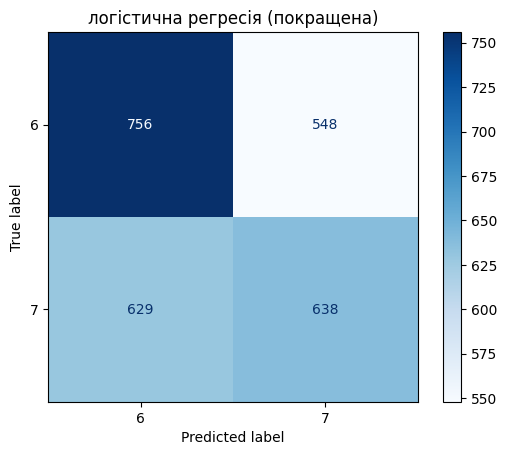

In [41]:
logreg2 = make_pipeline(StandardScaler(),
                        LogisticRegressionCV(Cs=[0.001, 0.003, 0.01, 0.03, 0.1, 1],
                                             cv=5, max_iter=3000))
cv_scores = cross_val_score(logreg2, F2_train, y_train_clean, cv=cv)
print(f"крос-валідація: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

logreg2.fit(F2_train, y_train_clean)
print("обране C:", logreg2[-1].C_[0])
y_pred_logreg2 = logreg2.predict(F2_test)
evaluate("логістична регресія (покращена)", y_test, y_pred_logreg2)

крос-валідація: 0.529 ± 0.005
=== random forest (покращений): accuracy на тесті = 0.537 (випадковість = 0.507) ===
              precision    recall  f1-score   support

           6      0.538     0.613     0.573      1304
           7      0.535     0.459     0.494      1267

    accuracy                          0.537      2571
   macro avg      0.537     0.536     0.534      2571
weighted avg      0.537     0.537     0.534      2571



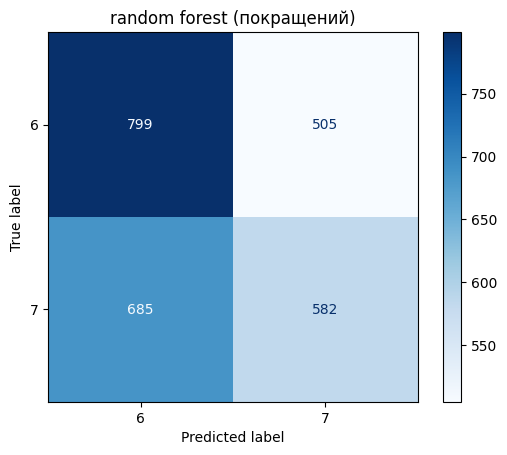

In [42]:
rf2 = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                             n_jobs=-1, random_state=RANDOM_STATE)
cv_scores = cross_val_score(rf2, F2_train, y_train_clean, cv=cv)
print(f"крос-валідація: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

rf2.fit(F2_train, y_train_clean)
y_pred_rf2 = rf2.predict(F2_test)
evaluate("random forest (покращений)", y_test, y_pred_rf2)

## аугментація і ансамбль

аугментація — під час навчання мережа щоразу бачить трохи змінену копію запису:
- випадкове вікно 224 з 250 відліків (зсув у часі до ~0.2 с)
- випадкове масштабування амплітуди в межах ±10%
- невеликий випадковий шум

так мережа не може просто «запам'ятати» конкретні приклади й мусить шукати стійкіші закономірності. під час перевірки мережа отримує повний запис без змін: завдяки шару усереднення по часу вона працює з будь-якою довжиною сигналу

додатково швидкість навчання плавно зменшується

ансамбль — тренуємо 5 однакових мереж з різною початковою випадковістю й усереднюємо їхні ймовірності. помилки окремих мереж частково випадкові, тож при усередненні вони взаємно гасяться

мережі тренуються на відфільтрованих і очищених даних. найкращу епоху кожної мережі, як і раніше, обираємо за валідаційною вибіркою. навчання 5 мереж на GPU займає кілька хвилин

In [43]:
idx_tr_clean = idx_tr[ptp[idx_tr] <= threshold]

mean_f = Xf[idx_tr_clean].mean(axis=(0, 2), keepdims=True)
std_f = Xf[idx_tr_clean].std(axis=(0, 2), keepdims=True) + 1e-6
Xfn = ((Xf - mean_f) / std_f).astype(np.float32)

def loader_from(Xdata, indices, shuffle):
    ds = TensorDataset(torch.from_numpy(Xdata[indices]),
                       torch.from_numpy(y_idx[indices]).long())
    return DataLoader(ds, batch_size=64, shuffle=shuffle, drop_last=shuffle)

def predict_proba(model, loader):
    model.eval()
    out = []
    with torch.no_grad():
        for xb, _ in loader:
            out.append(torch.softmax(model(xb.to(device)), dim=1).cpu().numpy())
    return np.concatenate(out)

CROP = 224

def train_cnn(seed, epochs=40):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = SmallEEGCNN().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    train_ld = loader_from(Xfn, idx_tr_clean, shuffle=True)
    val_ld = loader_from(Xfn, idx_val, shuffle=False)
    best_val, best_state, val_hist = 0.0, None, []
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_ld:
            xb, yb = xb.to(device), yb.to(device)
            start = np.random.randint(0, xb.shape[-1] - CROP + 1)
            xb = xb[:, :, start:start + CROP]
            xb = xb * torch.empty(len(xb), 1, 1, device=device).uniform_(0.9, 1.1)
            xb = xb + 0.1 * torch.randn_like(xb)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
        sched.step()
        val_acc = accuracy_score(y_idx[idx_val], predict(model, val_ld))
        val_hist.append(val_acc)
        if val_acc > best_val:
            best_val = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_val, val_hist

мережа 1/5: найкраща accuracy на валідації = 0.592 (26 с)
мережа 2/5: найкраща accuracy на валідації = 0.578 (26 с)
мережа 3/5: найкраща accuracy на валідації = 0.578 (26 с)
мережа 4/5: найкраща accuracy на валідації = 0.570 (26 с)
мережа 5/5: найкраща accuracy на валідації = 0.579 (26 с)

ансамбль на валідації: 0.572


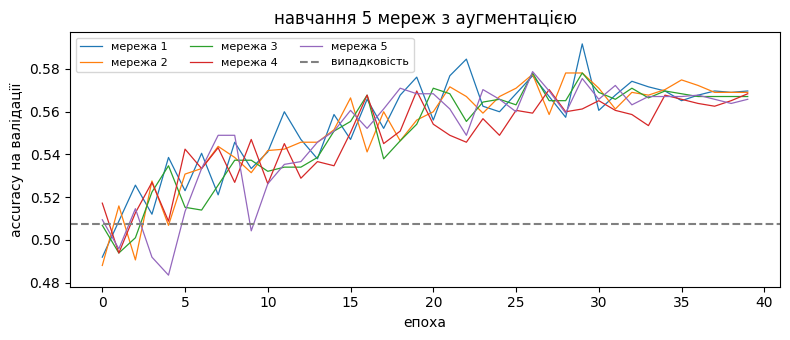

=== 1D-CNN + фільтр + аугментація: accuracy на тесті = 0.573 (випадковість = 0.507) ===
              precision    recall  f1-score   support

           6      0.559     0.748     0.640      1304
           7      0.602     0.391     0.474      1267

    accuracy                          0.573      2571
   macro avg      0.580     0.570     0.557      2571
weighted avg      0.580     0.573     0.558      2571



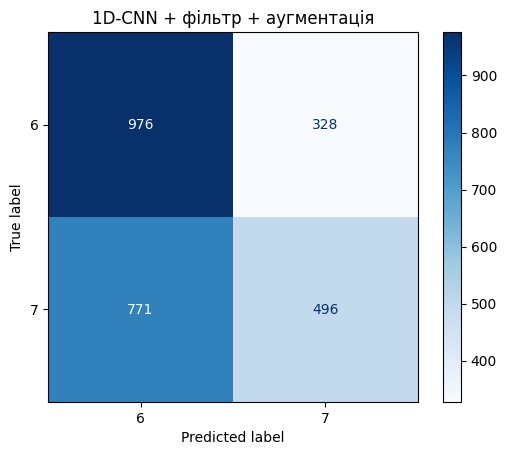

=== ансамбль 5 × 1D-CNN: accuracy на тесті = 0.583 (випадковість = 0.507) ===
              precision    recall  f1-score   support

           6      0.565     0.775     0.654      1304
           7      0.625     0.386     0.477      1267

    accuracy                          0.583      2571
   macro avg      0.595     0.581     0.566      2571
weighted avg      0.595     0.583     0.567      2571



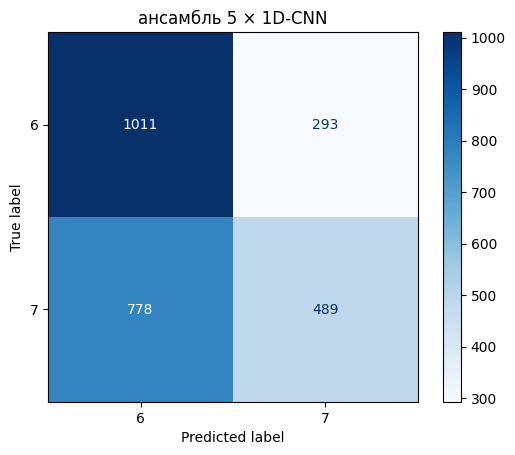

In [44]:
N_MODELS = 5
val_ld = loader_from(Xfn, idx_val, shuffle=False)
test_ld = loader_from(Xfn, idx_test, shuffle=False)

val_probs, test_probs, val_hists = [], [], []
for i in range(N_MODELS):
    t0 = time.time()
    m, best_val, hist = train_cnn(seed=100 + i)
    val_probs.append(predict_proba(m, val_ld))
    test_probs.append(predict_proba(m, test_ld))
    val_hists.append(hist)
    print(f"мережа {i + 1}/{N_MODELS}: найкраща accuracy на валідації = {best_val:.3f} "
          f"({time.time() - t0:.0f} с)")

ens_val_acc = accuracy_score(y_idx[idx_val], np.mean(val_probs, axis=0).argmax(axis=1))
print(f"\nансамбль на валідації: {ens_val_acc:.3f}")

plt.figure(figsize=(8, 3.5))
for i, h in enumerate(val_hists):
    plt.plot(h, lw=0.9, label=f"мережа {i + 1}")
plt.axhline(chance, ls="--", c="gray", label="випадковість")
plt.xlabel("епоха"); plt.ylabel("accuracy на валідації")
plt.title("навчання 5 мереж з аугментацією"); plt.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

y_pred_cnn_aug = classes[test_probs[0].argmax(axis=1)]
y_pred_ens = classes[np.mean(test_probs, axis=0).argmax(axis=1)]
evaluate("1D-CNN + фільтр + аугментація", y_test, y_pred_cnn_aug)
evaluate("ансамбль 5 × 1D-CNN", y_test, y_pred_ens)

## до/після

перша таблиця — усі моделі на тій самій тестовій вибірці, з p-value проти випадковості

друга таблиця показує, чи покращена модель дійно краща за стару, чи різниця випадкова. якщо p-value < 0.05, покращення статистично значуще

,модель,accuracy,p-value (vs випадковість)
0,baseline,0.5072,0.5079
1,логістична регресія,0.5235,0.0508
2,random forest,0.5344,0.0030
3,1D-CNN,0.5760,0.0000
4,логістична регресія (покращена),0.5422,0.0002
5,random forest (покращений),0.5371,0.0013
6,1D-CNN + фільтр + аугментація,0.5725,0.0000
7,ансамбль 5 × 1D-CNN,0.5834,0.0000


,модель,до,після,права лише стара,права лише нова,p-value
0,логістична регресія,0.5235,0.5422,319,367,0.0727
1,random forest,0.5344,0.5371,439,446,0.8402
2,1D-CNN (vs ансамбль),0.5760,0.5834,591,610,0.6035


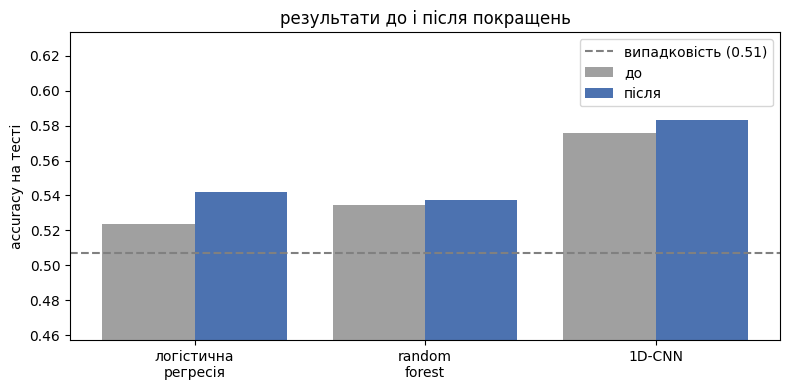

In [45]:
n_test = len(y_test)
table_all = pd.DataFrame([
    {"модель": name, "accuracy": r["accuracy"],
     "p-value (vs випадковість)": binomtest(r["n_correct"], n_test, chance,
                                            alternative="greater").pvalue}
    for name, r in results.items()
])
display(table_all.round(4))

def mcnemar(y_true, pred_old, pred_new):
    old_ok, new_ok = pred_old == y_true, pred_new == y_true
    b = int((old_ok & ~new_ok).sum())
    c = int((~old_ok & new_ok).sum())
    p = binomtest(c, b + c, 0.5).pvalue if b + c > 0 else 1.0
    return b, c, p

pairs = [
    ("логістична регресія", logreg.predict(F_test), y_pred_logreg2),
    ("random forest", rf.predict(F_test), y_pred_rf2),
    ("1D-CNN (vs ансамбль)", y_pred_cnn, y_pred_ens),
]
rows = []
for name, old, new in pairs:
    b, c, p = mcnemar(y_test, old, new)
    rows.append({"модель": name,
                 "до": accuracy_score(y_test, old), "після": accuracy_score(y_test, new),
                 "права лише стара": b, "права лише нова": c, "p-value": p})
table_pairs = pd.DataFrame(rows)
display(table_pairs.round(4))

x = np.arange(len(table_pairs))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, table_pairs["до"], width=0.4, label="до", color="#A0A0A0")
plt.bar(x + 0.2, table_pairs["після"], width=0.4, label="після", color="#4C72B0")
plt.axhline(chance, ls="--", c="gray", label=f"випадковість ({chance:.2f})")
plt.xticks(x, ["логістична\nрегресія", "random\nforest", "1D-CNN"])
plt.ylim(max(0, chance - 0.05), min(1, table_pairs[["до", "після"]].values.max() + 0.05))
plt.ylabel("accuracy на тесті"); plt.title("результати до і після покращень")
plt.legend(); plt.tight_layout(); plt.show()

In [46]:
import platform
from sklearn.base import clone

def timed(fn, repeats=1):
    times, out = [], None
    for _ in range(repeats):
        t0 = time.perf_counter()
        out = fn()
        times.append(time.perf_counter() - t0)
    return out, float(np.median(times))

timing = []
n_all, n_test = len(y), len(idx_test)

print("CPU:", platform.processor() or platform.machine(), "| ядер:", os.cpu_count())

_, t_feat1 = timed(lambda: band_power_features(X), repeats=3)
_, t_filter = timed(lambda: sosfiltfilt(sos, X, axis=-1), repeats=3)
_, t_feat2 = timed(lambda: better_features(Xf), repeats=3)
print(f"70 ознак: {t_feat1:.2f} с | фільтр: {t_filter:.2f} с | 378 ознак: {t_feat2:.2f} с")

def time_sklearn(name, model, Ftr, ytr, Fte, prep_time, count_params):
    m = clone(model)
    _, t_fit = timed(lambda: m.fit(Ftr, ytr))
    m.predict(Fte)
    _, t_pred = timed(lambda: m.predict(Fte), repeats=5)
    timing.append({"модель": name, "підготовка даних, с": prep_time, "навчання, с": t_fit,
                   "передбачення тесту, с": t_pred, "на один запис, мс": t_pred / n_test * 1000,
                   "мараметрів": count_params(m), "обладнання": "CPU"})
    print(f"{name}: навчання {t_fit:.2f} с, передбачення {t_pred:.4f} с")

lr_params = lambda m: int(m[-1].coef_.size + m[-1].intercept_.size)
rf_params = lambda m: int(sum(t.tree_.node_count for t in m.estimators_))

time_sklearn("логістична регресія", logreg, F_train, y_train, F_test, t_feat1, lr_params)
time_sklearn("random forest", rf, F_train, y_train, F_test, t_feat1, rf_params)
time_sklearn("логістична регресія (покращена)", logreg2, F2_train, y_train_clean, F2_test,
             t_filter + t_feat2, lr_params)
time_sklearn("random forest (покращений)", rf2, F2_train, y_train_clean, F2_test,
             t_filter + t_feat2, rf_params)

CPU: x86_64 | ядер: 2
70 ознак: 1.54 с | фільтр: 1.52 с | 378 ознак: 1.42 с
логістична регресія: навчання 0.35 с, передбачення 0.0060 с
random forest: навчання 29.83 с, передбачення 0.1387 с
логістична регресія (покращена): навчання 10.86 с, передбачення 0.0239 с
random forest (покращений): навчання 64.69 с, передбачення 0.1520 с


In [47]:
hw = torch.cuda.get_device_name(0) if device == "cuda" else "CPU"
print("нейромережі навчаються на:", hw)

def sync():
    if device == "cuda":
        torch.cuda.synchronize()

def time_train(fn):
    sync(); t0 = time.perf_counter()
    out = fn()
    sync()
    return out, time.perf_counter() - t0

def time_predict(fn, repeats=5):
    fn()
    ts = []
    for _ in range(repeats):
        sync(); t0 = time.perf_counter()
        fn()
        sync()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

def train_plain(seed=RANDOM_STATE, epochs=40):
    torch.manual_seed(seed)
    model = SmallEEGCNN().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)
    best_val, best_state = 0.0, None
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
        val_acc = accuracy_score(y_idx[idx_val], predict(model, val_loader))
        if val_acc > best_val:
            best_val = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model

cnn_t, t_fit = time_train(train_plain)
t_pred = time_predict(lambda: predict(cnn_t, test_loader))
timing.append({"модель": "1D-CNN", "підготовка даних, с": 0.0, "навчання, с": t_fit,
               "передбачення тесту, с": t_pred, "на один запис, мс": t_pred / n_test * 1000,
               "параметрів": n_params, "обладнання": hw})
print(f"1D-CNN: навчання {t_fit:.1f} с, передбачення {t_pred:.4f} с, "
      f"accuracy цього запуску {accuracy_score(y_idx[idx_test], predict(cnn_t, test_loader)):.3f}")
nets, net_times = [], []
for i in range(N_MODELS):
    (m_i, _, _), t_i = time_train(lambda: train_cnn(seed=100 + i))
    nets.append(m_i)
    net_times.append(t_i)
    print(f"мережа {i + 1}/{N_MODELS}: навчання {t_i:.1f} с")

t_pred1 = time_predict(lambda: predict_proba(nets[0], test_ld))
t_pred5 = time_predict(lambda: [predict_proba(m_i, test_ld) for m_i in nets])
timing.append({"модель": "1D-CNN + фільтр + аугментація", "підготовка даних, с": t_filter,
               "навчання, с": net_times[0], "передбачення тесту, с": t_pred1,
               "на один запис, мс": t_pred1 / n_test * 1000, "параметрів": n_params, "обладнання": hw})
timing.append({"модель": "ансамбль 5 × 1D-CNN", "підготовка даних, с": t_filter,
               "навчання, с": sum(net_times), "передбачення тесту, с": t_pred5,
               "на один запис, мс": t_pred5 / n_test * 1000, "параметрів": n_params * N_MODELS,
               "обладнання": hw})

нейромережі навчаються на: Tesla T4
1D-CNN: навчання 27.3 с, передбачення 0.0949 с, accuracy цього запуску 0.588
мережа 1/5: навчання 27.4 с
мережа 2/5: навчання 27.6 с
мережа 3/5: навчання 36.3 с
мережа 4/5: навчання 26.9 с
мережа 5/5: навчання 26.9 с


In [48]:
table_time = pd.DataFrame(timing)
display(table_time.round({"підготовка даних, с": 2, "навчання, с": 2,
                          "передбачення тесту, с": 4, "на один запис, мс": 4}))
print("підготовка даних — для всіх", n_all, "записів; передбачення — для", n_test, "тестових")

,модель,"підготовка даних, с","навчання, с","передбачення тесту, с","на один запис, мс",мараметрів,обладнання,параметрів
0,логістична регресія,1.54,0.35,0.0060,0.0023,71.0,CPU,NaN
1,random forest,1.54,29.83,0.1387,0.0540,515830.0,CPU,NaN
2,логістична регресія (покращена),2.94,10.86,0.0239,0.0093,379.0,CPU,NaN
3,random forest (покращений),2.94,64.69,0.1520,0.0591,444544.0,CPU,NaN
4,1D-CNN,0.00,27.30,0.0949,0.0369,NaN,Tesla T4,34466.0
5,1D-CNN + фільтр + аугментація,1.52,27.43,0.0777,0.0302,NaN,Tesla T4,34466.0
6,ансамбль 5 × 1D-CNN,1.52,145.16,0.3628,0.1411,NaN,Tesla T4,172330.0


п даних — для всіх 12853 записів; передбачення — для 2571 тестових.
